# Which Iranian assets beat inflation, and which beat the dollar?

Every bar and line below is one `yfinance_ir` call: TSETMC indices, stocks and ETFs,
TGJU's dollar, euro, gold and coin, Nobitex bitcoin, measured against the two yardsticks
Iranians actually use, the Statistical Centre of Iran CPI and the free-market dollar.
Nothing is typed in by hand except one CPI month that SCI has announced but not yet put in its
workbook (see *Two yardsticks*); re-running the notebook on a later date redraws every chart.

The anchor is Nowruz 1405 (21 March 2026). An asset *beat inflation* when its
CPI-deflated return since the last quote before Nowruz is positive, and *beat the dollar*
when its return measured in dollars is positive. Prices are Rial, adjusted for dividends
and capital increases (`docs/conventions.md`); bitcoin is Nobitex's Toman quote times ten.
Needs an Iranian IP and `pip install "yfinance-ir[crypto,notebook]"`. Outputs below were
produced on the date printed in the first cell.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import datetime as dt
import warnings
from pathlib import Path

import arabic_reshaper
import jdatetime
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from bidi import get_display
from matplotlib import font_manager as fm
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

import yfinance_ir as yf

warnings.simplefilter("ignore", FutureWarning)


def fa(text):
    """Persian for matplotlib. 3.11+ shapes and orders right-to-left text itself; older versions
    need reshape (join the letters) and bidi (lay them out right-to-left), line by line.
    Signed numbers go on their own line: next to Persian words the bidi algorithm moves the
    sign to the far side ("29%+")."""
    text = str(text)
    if matplotlib.__version_info__ >= (3, 11):
        return text
    return "\n".join(get_display(arabic_reshaper.reshape(line)) for line in text.split("\n"))


FA_DIGITS = str.maketrans("0123456789", "۰۱۲۳۴۵۶۷۸۹")
MONTHS_FA = ["فروردین", "اردیبهشت", "خرداد", "تیر", "مرداد", "شهریور",
             "مهر", "آبان", "آذر", "دی", "بهمن", "اسفند"]


def jalali(ts):
    """Timestamp -> '۱۶ مهر ۱۴۰۵'."""
    j = jdatetime.date.fromgregorian(date=pd.Timestamp(ts).date())
    return f"{j.day} {MONTHS_FA[j.month - 1]} {j.year}".translate(FA_DIGITS)


# fonts installed after matplotlib built its cache are invisible until added explicitly
for path in fm.findSystemFonts():
    if "Vazirmatn" in Path(path).name:
        fm.fontManager.addfont(path)
HAS_VAZIR = any(f.name == "Vazirmatn" for f in fm.fontManager.ttflist)
plt.rcParams["font.family"] = ["Vazirmatn", "DejaVu Sans"] if HAS_VAZIR else ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (14, 7)

TODAY = pd.Timestamp.today().normalize()
JYEAR = jdatetime.date.today().year
NOWRUZ = pd.Timestamp(jdatetime.date(JYEAR, 1, 1).togregorian())
START = TODAY - pd.DateOffset(years=5, months=2)  # two CPI months before the 5-year window opens
CREDIT = "yfinance-ir · github.com/Fazel94/yfinance-ir · TSETMC · TGJU · SCI · Nobitex"
PCT = FuncFormatter(lambda v, _: f"{v:+.0%}")

print("run on", dt.date.today(), "| yfinance_ir", yf.__version__, "| font", plt.rcParams["font.family"][0])

run on 2026-10-09 | yfinance_ir 2026.9.2 | font Vazirmatn


## The assets

Eleven instruments from four sources, each one `Ticker(symbol).history(start=...)`. The
dollar is both an asset and a yardstick. A source that fails (TSETMC's CDN is flaky, the
`crypto` extra may be missing) drops that row and prints why instead of stopping the
notebook. The coverage table shows where each series starts and ends, plus its last bar before
Nowruz and the first bar after it on which the price moved: a TSETMC symbol that was closed
across Nowruz keeps its last pre-closure price until it reopens, and the index stays flat while
its constituents are closed.

In [2]:
ASSETS = {  # chart label -> yfinance_ir symbol
    "شاخص کل بورس": "شاخص کل",
    "شاخص کل هم وزن": "شاخص کل (هم وزن)",
    "سهم فولاد مبارکه": "فولاد",
    "سهم ملی مس": "فملی",
    "صندوق اهرمی اهرم": "اهرم",
    "صندوق درآمد ثابت آوند": "آوند",
    "دلار آزاد": "USD",
    "یورو آزاد": "EUR",
    "طلای ۱۸ عیار": "GOLD18",
    "سکه تمام امامی": "COIN",
    "بیت کوین (نوبیتکس)": "BTC-IRT",
}
USD = "دلار آزاد"

closes, failed = {}, {}
for label, symbol in ASSETS.items():
    try:
        close = yf.Ticker(symbol).history(start=START)["Close"]
    except yf.YFIRError as exc:
        failed[label] = f"{symbol}: {type(exc).__name__}: {exc}"
        continue
    closes[label] = close * 10 if symbol.endswith("-IRT") else close  # Toman -> Rial
closes = pd.DataFrame(closes).sort_index()
assert USD in closes, "no dollar series, nothing to measure against"
for label, why in failed.items():
    print("skipped", label, "->", why)



def day(ts):
    return None if ts is None else ts.date()


def first_move(series):
    """First bar at or after Nowruz whose close differs from the last close before Nowruz."""
    series = series.dropna()
    before, after = series.loc[: NOWRUZ - pd.Timedelta(days=1)], series.loc[NOWRUZ:]
    moved = after[after != before.iloc[-1]] if len(before) else after
    return moved.index[0] if len(moved) else None


coverage = pd.DataFrame(
    {
        "symbol": [ASSETS[label] for label in closes],
        "first": [day(closes[label].first_valid_index()) for label in closes],
        "last before Nowruz": [day(closes[label].loc[: NOWRUZ - pd.Timedelta(days=1)].last_valid_index())
                               for label in closes],
        "first move after Nowruz": [day(first_move(closes[label])) for label in closes],
        "last": [day(closes[label].last_valid_index()) for label in closes],
        "bars": closes.count().to_numpy(),
    },
    index=closes.columns,
)
frozen = coverage.index[pd.to_datetime(coverage["first move after Nowruz"]) > NOWRUZ + pd.Timedelta(days=14)]
if len(frozen):
    print("closed across Nowruz, price first moved on:",
          ", ".join(f"{label} {coverage.loc[label, 'first move after Nowruz']}" for label in frozen))
stale = coverage.index[pd.to_datetime(coverage["last"]) < TODAY - pd.Timedelta(days=10)]
if len(stale):
    print("stale, no bar in 10 days:", ", ".join(stale))
coverage

closed across Nowruz, price first moved on: شاخص کل بورس 2026-05-19, شاخص کل هم وزن 2026-05-19, سهم فولاد مبارکه 2026-08-08, سهم ملی مس 2026-05-19, صندوق اهرمی اهرم 2026-05-19


,symbol,first,last before Nowruz,first move after Nowruz,last,bars
شاخص کل بورس,شاخص کل,2021-08-09,2026-03-18,2026-05-19,2026-10-07,1238
شاخص کل هم وزن,شاخص کل (هم وزن),2021-08-09,2026-03-18,2026-05-19,2026-10-07,1238
سهم فولاد مبارکه,فولاد,2021-08-09,2026-02-25,2026-08-08,2026-10-07,1078
سهم ملی مس,فملی,2021-08-09,2026-02-25,2026-05-19,2026-10-07,1101
صندوق اهرمی اهرم,اهرم,2021-12-20,2026-02-25,2026-05-19,2026-10-07,1079
صندوق درآمد ثابت آوند,آوند,2022-07-16,2026-03-18,2026-03-25,2026-10-07,998
دلار آزاد,USD,2021-08-09,2026-03-19,2026-03-23,2026-10-08,1450
یورو آزاد,EUR,2021-08-09,2026-03-19,2026-03-23,2026-10-08,1465
طلای ۱۸ عیار,GOLD18,2021-08-09,2026-03-19,2026-03-23,2026-10-08,1466
سکه تمام امامی,COIN,2021-08-09,2026-03-19,2026-03-23,2026-10-08,1475


## Two yardsticks

`Ticker("CPI")` is the Statistical Centre of Iran index: one level per Jalali month,
stamped on the month's first day and published a few weeks after it ends. It is
forward-filled onto the daily calendar, so the last few weeks carry the latest published
month and "real" returns are, if anything, slightly flattered. SCI announces each month in a
report weeks before the workbook catches up; a month announced but not yet in the workbook
is appended from the report and printed below, and the workbook wins once it has it. `Ticker("USD")` is TGJU's
free-market dollar in Rial, quoted on every trading day. Every window below opens on the
last quote *before* its start date, so "since Nowruz" means "since the last day of 1404". For a
symbol that was closed on that day it is the last trade before the closure, and the line stays
flat until the symbol reopens.

In [3]:
cpi_ticker = yf.Ticker("CPI")
cpi = cpi_ticker.history(start=START)["Close"]
# SCI's monthly report precedes its workbook by weeks. Months announced in the report but not
# yet in the workbook, as (Jalali month, index level on the workbook's 1400 = 100 base):
# Shahrivar 1405 = 729.8, +4.2% m/m, SCI report of 8 Mehr 1405 (iranwire.com/fa/news-1/158304).
SCI_REPORTED = {(1405, 6): 729.8}
for (year, month), level in SCI_REPORTED.items():
    stamp = pd.Timestamp(jdatetime.date(year, month, 1).togregorian())
    if stamp > cpi.index[-1]:
        print(f"CPI {jalali(stamp)} = {level} from the SCI report, not yet in the workbook")
        cpi.loc[stamp] = level
px = closes.ffill()
cpi_daily = cpi.reindex(px.index, method="ffill")
yoy = cpi.iloc[-1] / cpi.iloc[-13] - 1
print(f"CPI base year {cpi_ticker.info['baseYear']} = 100 | latest month {jalali(cpi.index[-1])} | "
      f"point-to-point inflation {yoy:+.1%}")

CPI ۱ شهریور ۱۴۰۵ = 729.8 from the SCI report, not yet in the workbook


CPI base year 1400 = 100 | latest month ۱ شهریور ۱۴۰۵ | point-to-point inflation +89.8%


## Since Nowruz: one bar per asset

Total nominal return in Rial from the last quote before 1 Farvardin to the latest bar,
sorted. The two vertical lines are the yardsticks over the same window: how much the CPI
rose and how much the dollar rose. A bar that ends to the right of both lines beat
inflation *and* the dollar; left of both, it lost to both; between them, it beat one and
not the other. The shaded bands mark those three zones. The dollar's own bar is grey: it is the yardstick. This figure is also
saved as `scoreboard.png`.

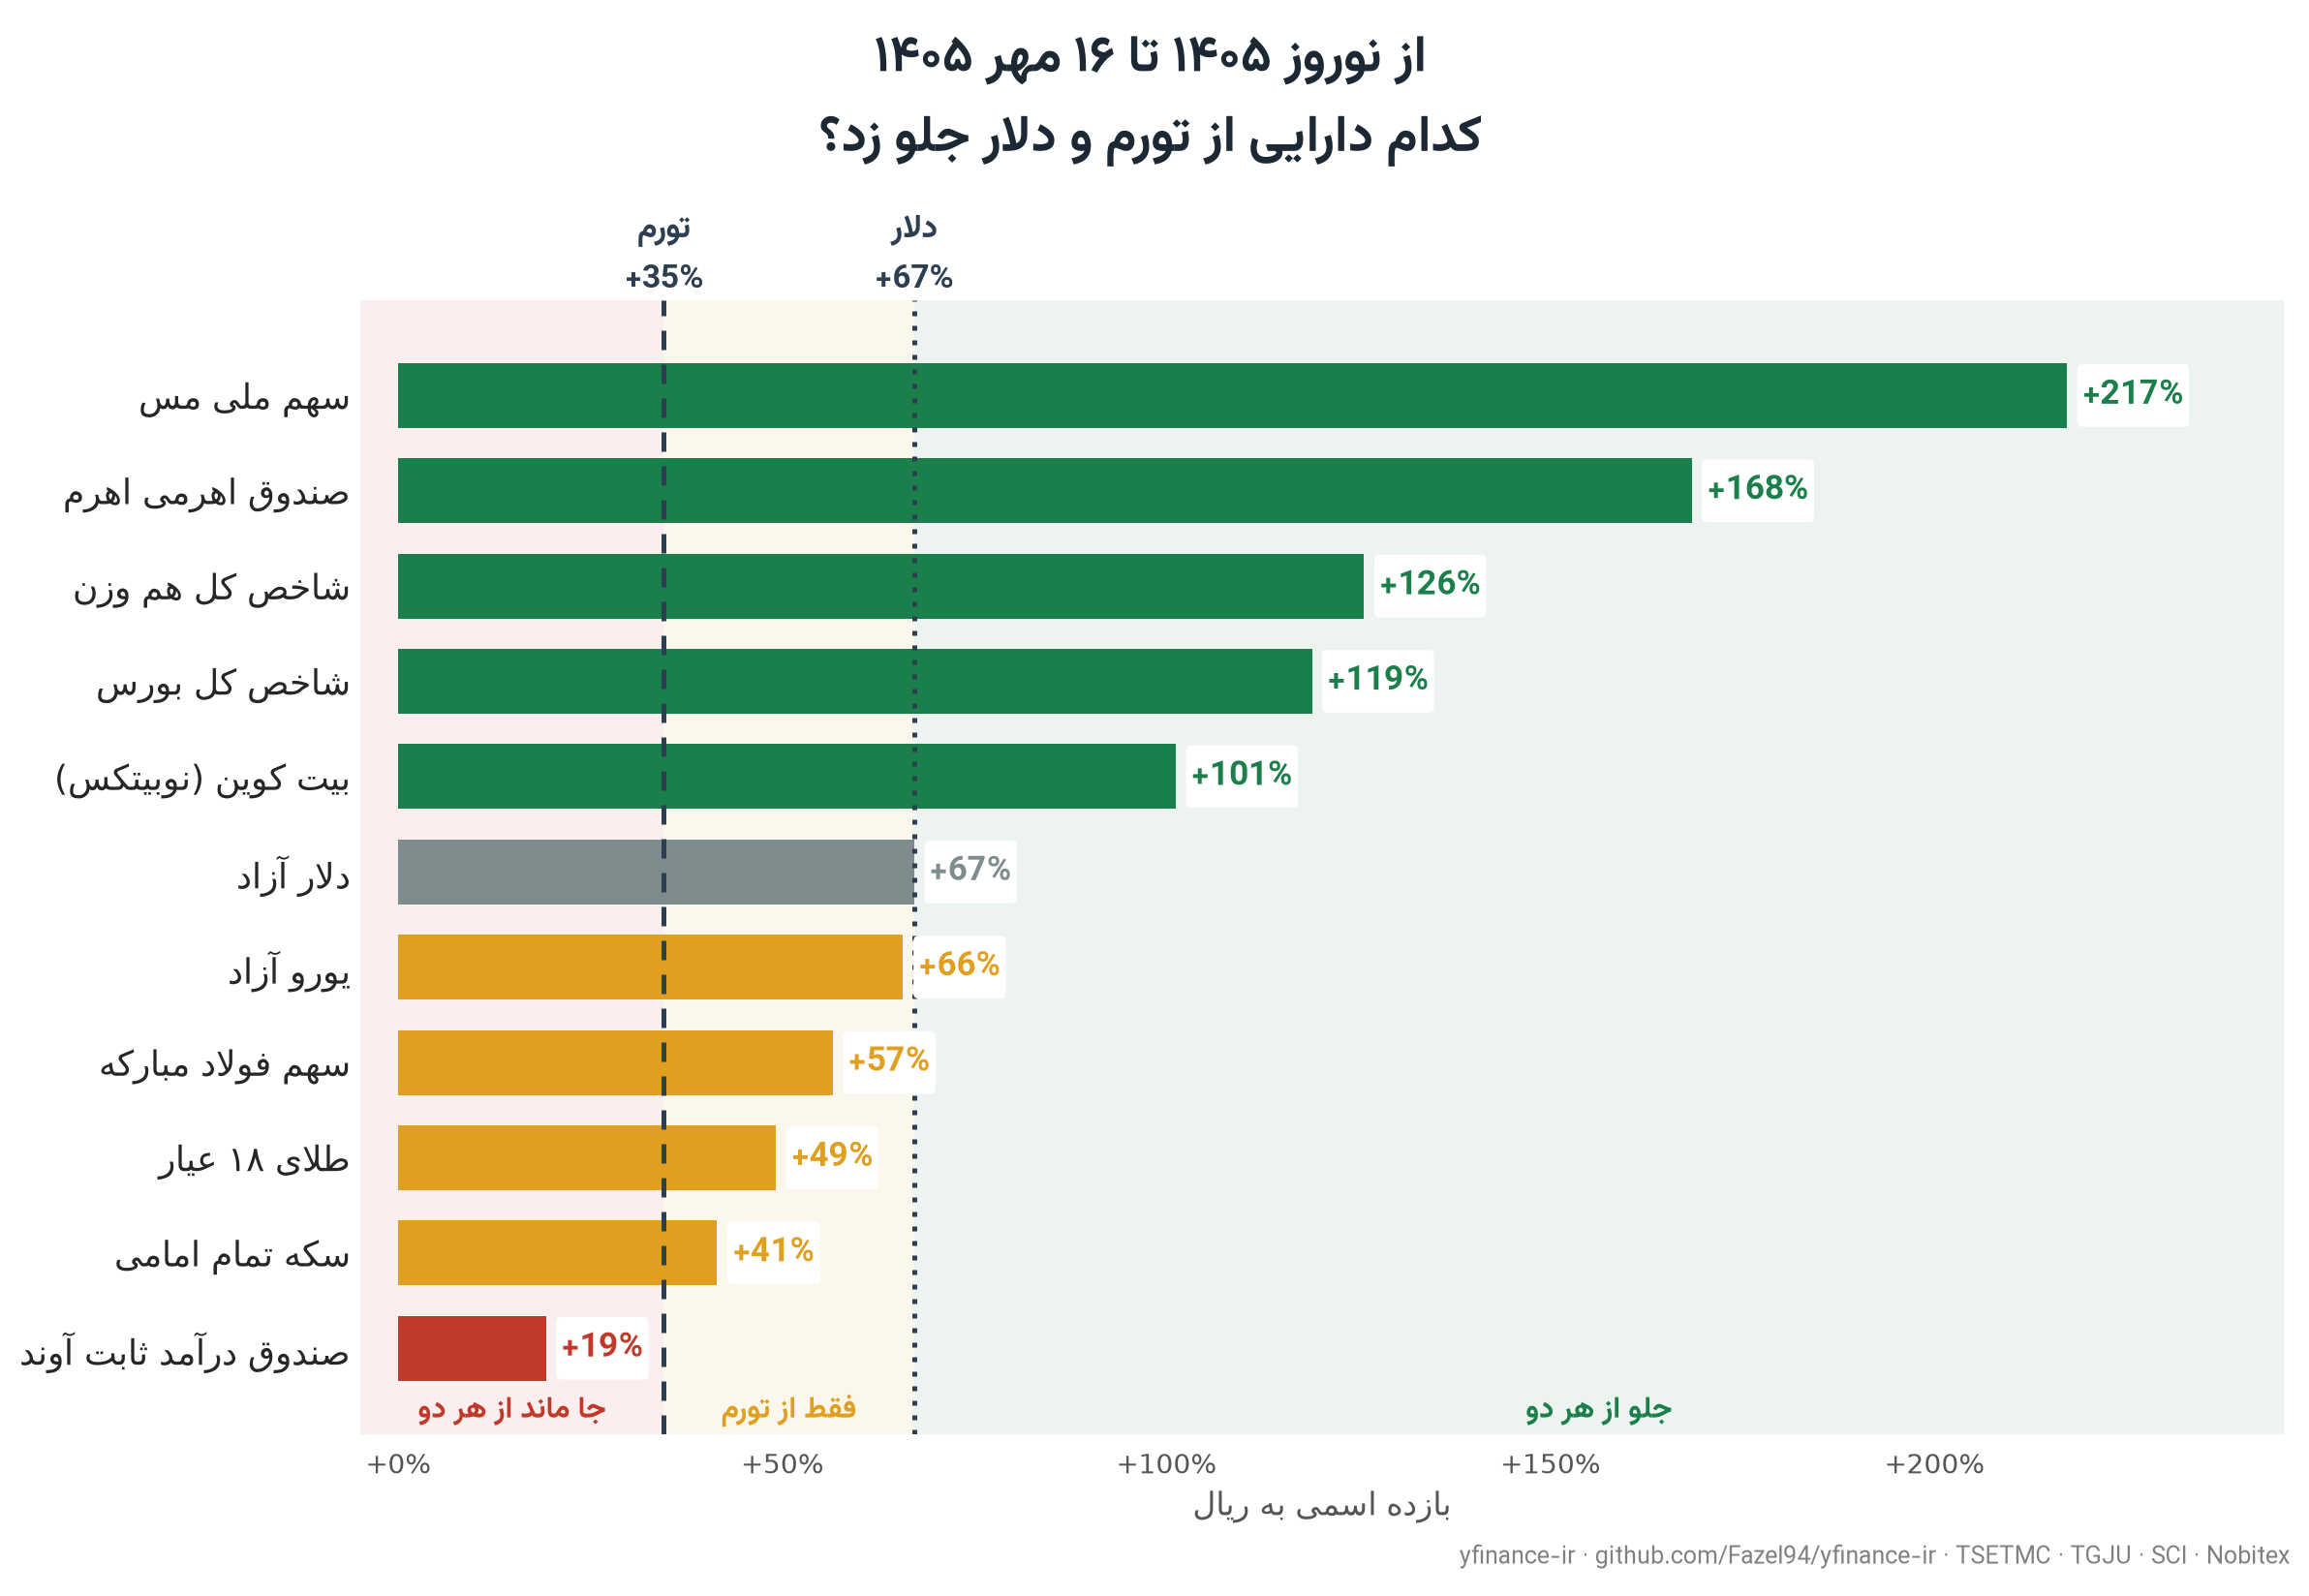

In [4]:
def window_returns(start):
    """Nominal, CPI-deflated and dollar total return from the last quote before ``start`` to the last bar.

    One row per asset; an asset with no quote before ``start`` (bitcoin on Nobitex begins in
    2025) is NaN for that window. Returns ``(table, inflation, dollar)`` with the two
    yardsticks' own moves.
    """
    base = px.loc[: pd.Timestamp(start) - pd.Timedelta(days=1)].index[-1]
    first, last = px.loc[base], px.iloc[-1]
    inflation = cpi_daily.iloc[-1] / cpi_daily.loc[base] - 1
    dollar = last[USD] / first[USD] - 1
    nominal = last / first - 1
    table = pd.DataFrame(
        {
            "nominal": nominal,
            "real": (1 + nominal) / (1 + inflation) - 1,
            "usd": (1 + nominal) / (1 + dollar) - 1,
        }
    )
    return table, inflation, dollar


GREEN, AMBER, RED, GREY = "#1b7f4b", "#e09f1f", "#c0392b", "#7f8c8d"
BOTH, NEITHER, BENCHMARK = "از تورم و دلار جلو زد", "از تورم و دلار جا ماند", "معیار"
ONLY_CPI, ONLY_USD = "از تورم جلو زد، از دلار جا ماند", "از دلار جلو زد، از تورم جا ماند"
COLORS = {BOTH: GREEN, NEITHER: RED, BENCHMARK: GREY, ONLY_CPI: AMBER, ONLY_USD: AMBER}
INK = "#2c3e50"


def verdict(row):
    if row.name == USD:
        return BENCHMARK
    ahead_cpi, ahead_usd = row["real"] > 0, row["usd"] > 0
    if ahead_cpi and ahead_usd:
        return BOTH
    if not ahead_cpi and not ahead_usd:
        return NEITHER
    return ONLY_CPI if ahead_cpi else ONLY_USD


def scoreboard(table, inflation, dollar, title, path=None):
    table = table.sort_values("nominal", ascending=False)
    lo, hi = min(0, table["nominal"].min()) - 0.05, table["nominal"].max() * 1.13
    with sns.axes_style("white"):
        fig, ax = plt.subplots(figsize=(12, 0.55 * len(table) + 2.2))
    # background zones: behind both yardsticks, beat inflation only, beat both
    zones = ((lo, inflation, RED, "جا ماند از هر دو"), (inflation, dollar, AMBER, "فقط از تورم"),
             (dollar, hi, GREEN, "جلو از هر دو"))
    for left, right, color, label in zones:
        ax.axvspan(left, right, color=color, alpha=0.08, lw=0)
        ax.text((left + right) / 2, len(table) - 0.35, fa(label), ha="center", va="center",
                fontsize=11, color=color, weight="bold")
    sns.barplot(x=table["nominal"], y=[fa(label) for label in table.index], hue=table["verdict"].to_numpy(),
                palette=COLORS, dodge=False, legend=False, ax=ax, width=0.68, saturation=1)
    for i, (value, v) in enumerate(zip(table["nominal"], table["verdict"])):
        ax.text(value + 0.02, i, f"{value:+.0%}", va="center", ha="left", fontsize=12.5, weight="bold",
                color=COLORS[v], bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
    for value, name, style in ((inflation, "تورم", (0, (4, 3))), (dollar, "دلار", (0, (1, 2)))):
        ax.axvline(value, color=INK, linestyle=style, linewidth=1.8, zorder=1)
        ax.text(value, -0.95, fa(f"{name}\n{value:+.0%}"), ha="center", va="bottom", fontsize=12,
                weight="bold", color=INK, multialignment="center")
    ax.set_xlim(lo, hi)
    ax.set_ylim(len(table) - 0.1, -1.0)
    ax.tick_params(axis="y", length=0, labelsize=13)
    ax.tick_params(axis="x", colors="#555")
    ax.set_ylabel("")
    ax.set_xlabel(fa("بازده اسمی به ریال"), fontsize=12, color="#555")
    ax.xaxis.set_major_formatter(PCT)
    ax.grid(axis="x", color="white", linewidth=1.2)
    sns.despine(ax=ax, left=True, bottom=True)
    fig.suptitle(fa(title), fontsize=19, weight="bold", color="#1c2833")
    fig.text(0.99, 0.005, CREDIT, ha="right", va="bottom", fontsize=9, color="grey")
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    if path:
        fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

ytd, inflation, dollar = window_returns(NOWRUZ)
ytd = ytd.dropna()
ytd["verdict"] = ytd.apply(verdict, axis=1)
title = f"از نوروز {JYEAR} تا {jalali(px.index[-1])}\nکدام دارایی از تورم و دلار جلو زد؟".translate(FA_DIGITS)
scoreboard(ytd, inflation, dollar, title, path="scoreboard.png")

In [5]:
summary = ytd.sort_values("nominal", ascending=False)
summary = pd.concat(
    [summary[["nominal", "real", "usd"]].map("{:+.1%}".format), summary["verdict"]], axis=1
).rename(columns={"nominal": "اسمی", "real": "واقعی (پس از تورم)", "usd": "دلاری", "verdict": "وضعیت"})
summary.index.name = "دارایی"
print(f"yardsticks since Nowruz: inflation {inflation:+.1%}, dollar {dollar:+.1%}")
summary

yardsticks since Nowruz: inflation +34.6%, dollar +67.1%


,اسمی,واقعی (پس از تورم),دلاری,وضعیت
دارایی,,,,
سهم ملی مس,+217.2%,+135.7%,+89.8%,از تورم و دلار جلو زد
صندوق اهرمی اهرم,+168.4%,+99.5%,+60.6%,از تورم و دلار جلو زد
شاخص کل هم وزن,+125.7%,+67.7%,+35.1%,از تورم و دلار جلو زد
شاخص کل بورس,+118.9%,+62.7%,+31.0%,از تورم و دلار جلو زد
بیت کوین (نوبیتکس),+101.2%,+49.5%,+20.4%,از تورم و دلار جلو زد
دلار آزاد,+67.1%,+24.2%,+0.0%,معیار
یورو آزاد,+65.7%,+23.1%,-0.8%,از تورم جلو زد، از دلار جا ماند
سهم فولاد مبارکه,+56.5%,+16.3%,-6.3%,از تورم جلو زد، از دلار جا ماند
طلای ۱۸ عیار,+49.1%,+10.8%,-10.8%,از تورم جلو زد، از دلار جا ماند


## 100 at Nowruz

The same window as a path: each asset indexed to 100 at the last quote before Nowruz, in
nominal Rial. The thick black line is the CPI, the cost of living; the dotted black line
is the dollar. A line under the black one buys less than it did at Nowruz; under the
dotted one, it is worth fewer dollars. The legend is sorted by where each line ends.

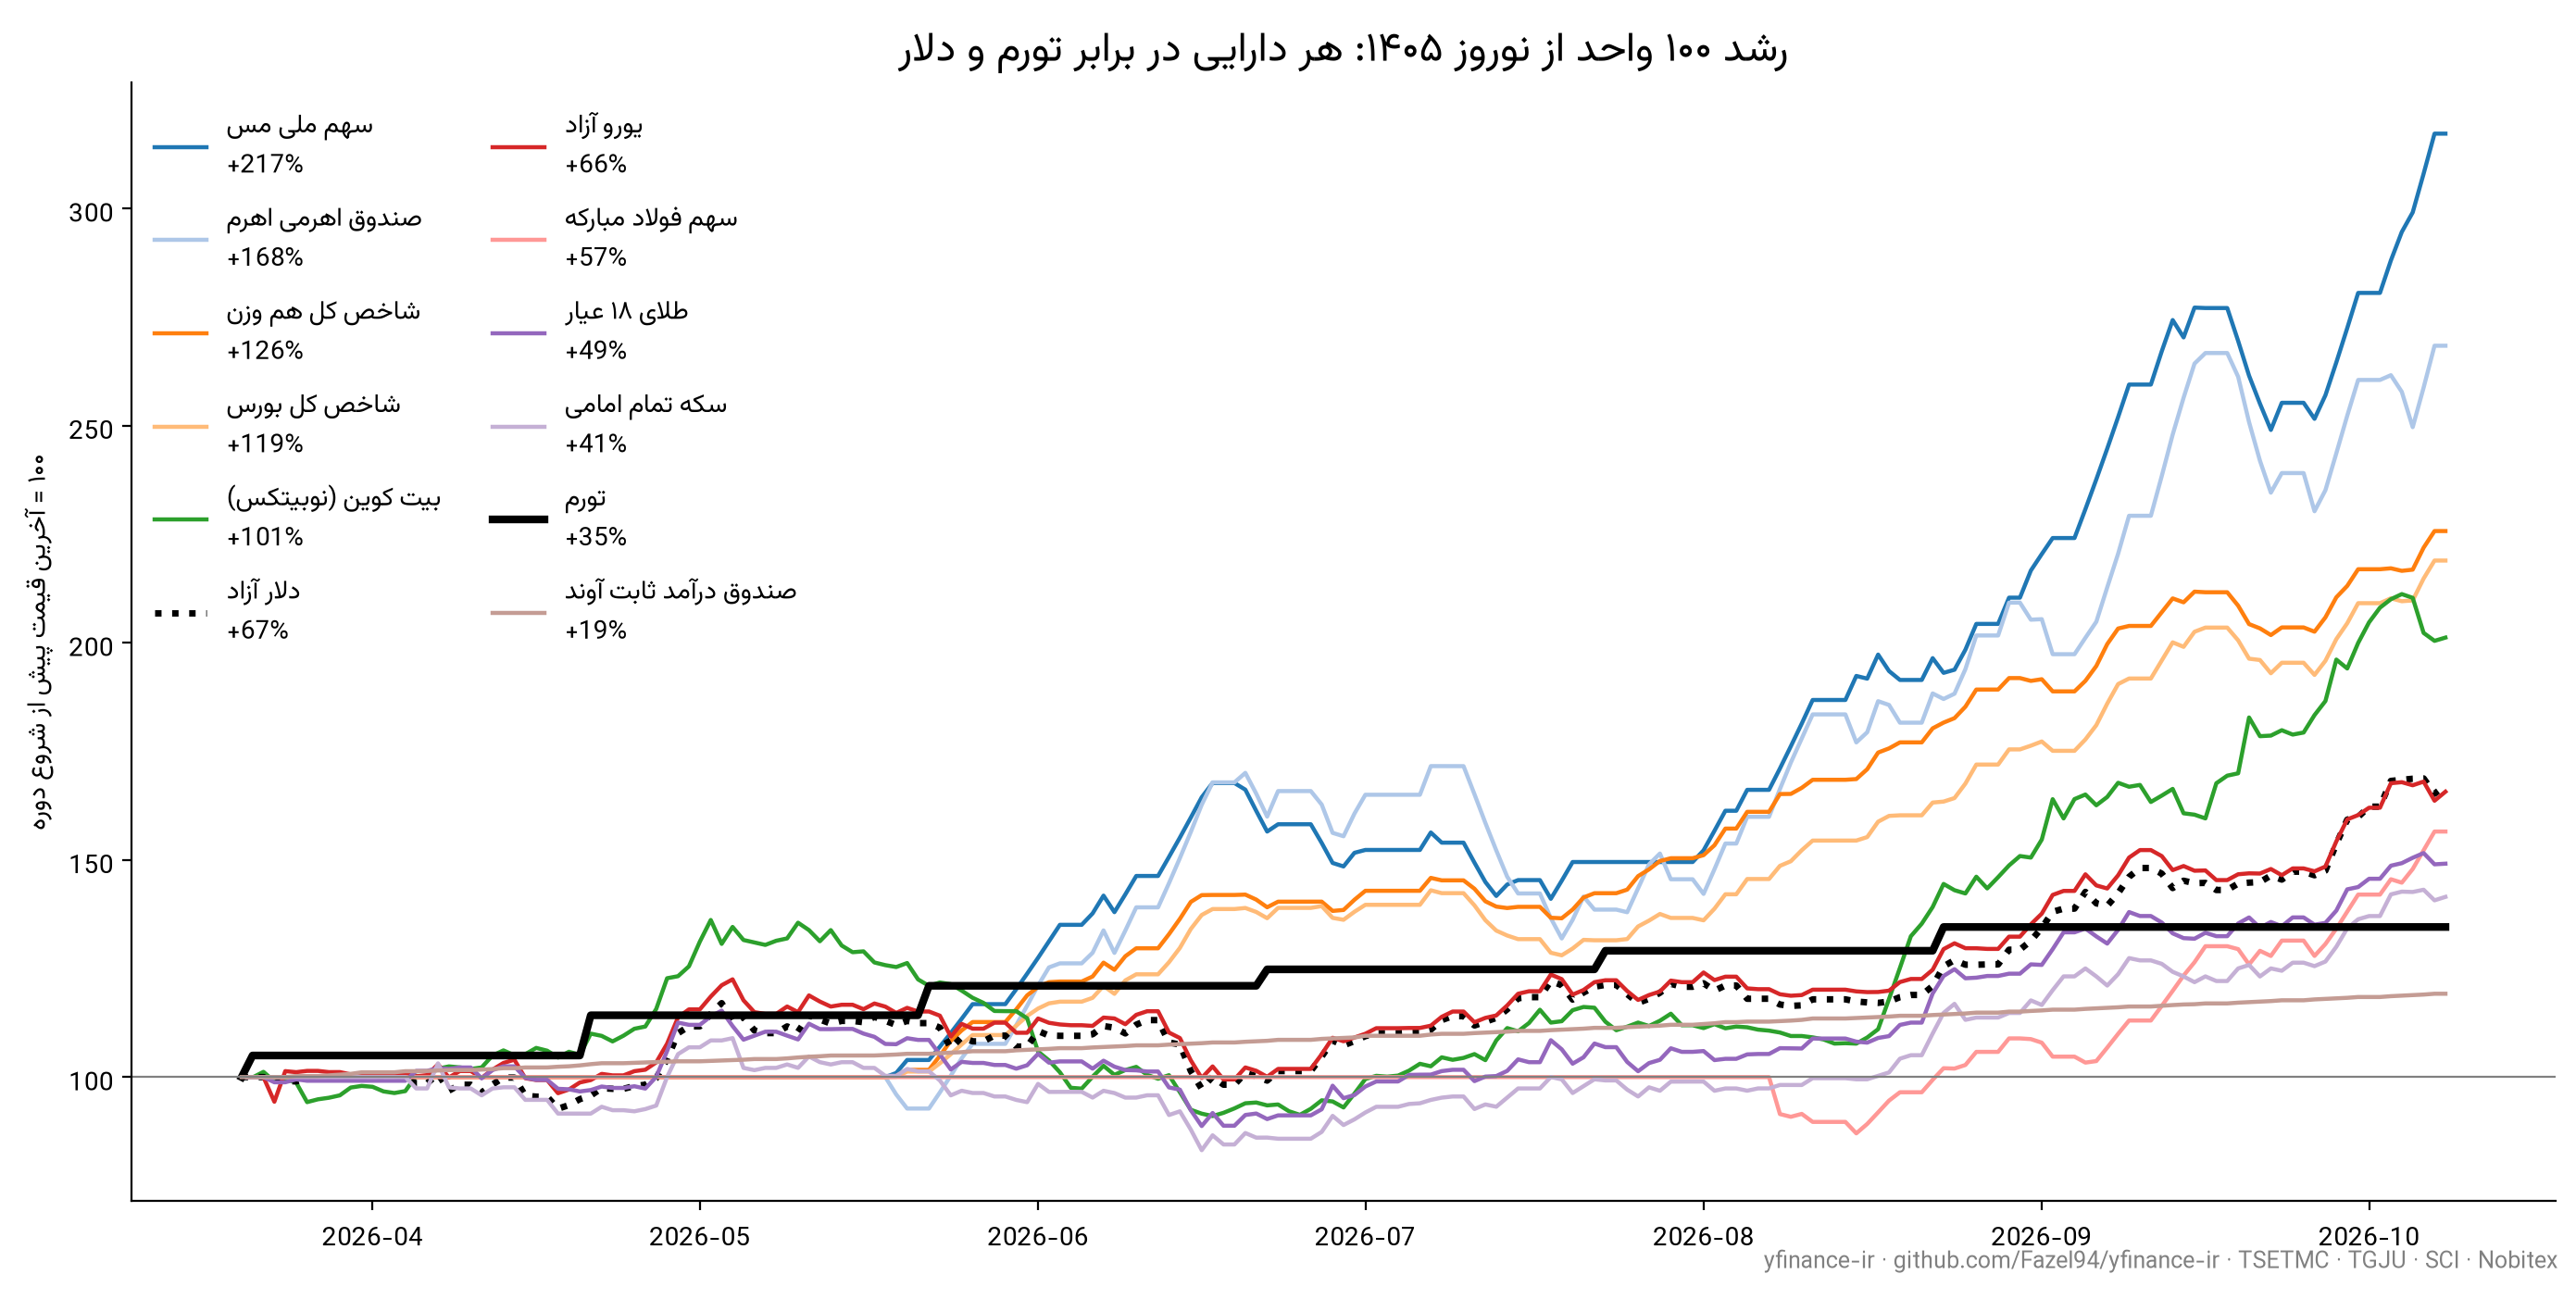

In [6]:
def race(start, title, log=False):
    """Every asset and the CPI indexed to 100 at the last quote before ``start``."""
    base = px.loc[: pd.Timestamp(start) - pd.Timedelta(days=1)].index[-1]
    frame = px.loc[base:].assign(**{"تورم": cpi_daily.loc[base:]})
    frame = frame / frame.loc[base] * 100
    missing = [label for label in frame if pd.isna(frame.loc[base, label])]
    frame = frame.drop(columns=missing)
    style = {USD: dict(color="black", linestyle=":", linewidth=2.5), "تورم": dict(color="black", linewidth=3)}
    palette = plt.get_cmap("tab20")
    fig, ax = plt.subplots(figsize=(14, 7))
    for i, label in enumerate(frame.iloc[-1].sort_values(ascending=False).index):
        kw = style.get(label, dict(color=palette(i), linewidth=1.6))
        end = frame[label].iloc[-1] / 100 - 1
        ax.plot(frame.index, frame[label], label=fa(f"{label}\n{end:+.0%}"), **kw)
    if log:
        ax.set_yscale("log")
    ax.axhline(100, color="grey", linewidth=0.8)
    ax.set_title(fa(title), fontsize=16)
    ax.set_ylabel(fa("۱۰۰ = آخرین قیمت پیش از شروع دوره"))
    ax.legend(loc="upper left", fontsize=10, frameon=False, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)
    fig.text(0.99, 0.005, CREDIT, ha="right", va="bottom", fontsize=9, color="grey")
    fig.tight_layout()
    plt.show()
    if missing:
        print("not on this chart, data starts after the window opens:", ", ".join(missing))


race(NOWRUZ, f"رشد ۱۰۰ واحد از نوروز {JYEAR}: هر دارایی در برابر تورم و دلار".translate(FA_DIGITS))

### The long view

Five years, log scale, same construction. Assets whose data starts after the window opens
are left out and listed under the chart.

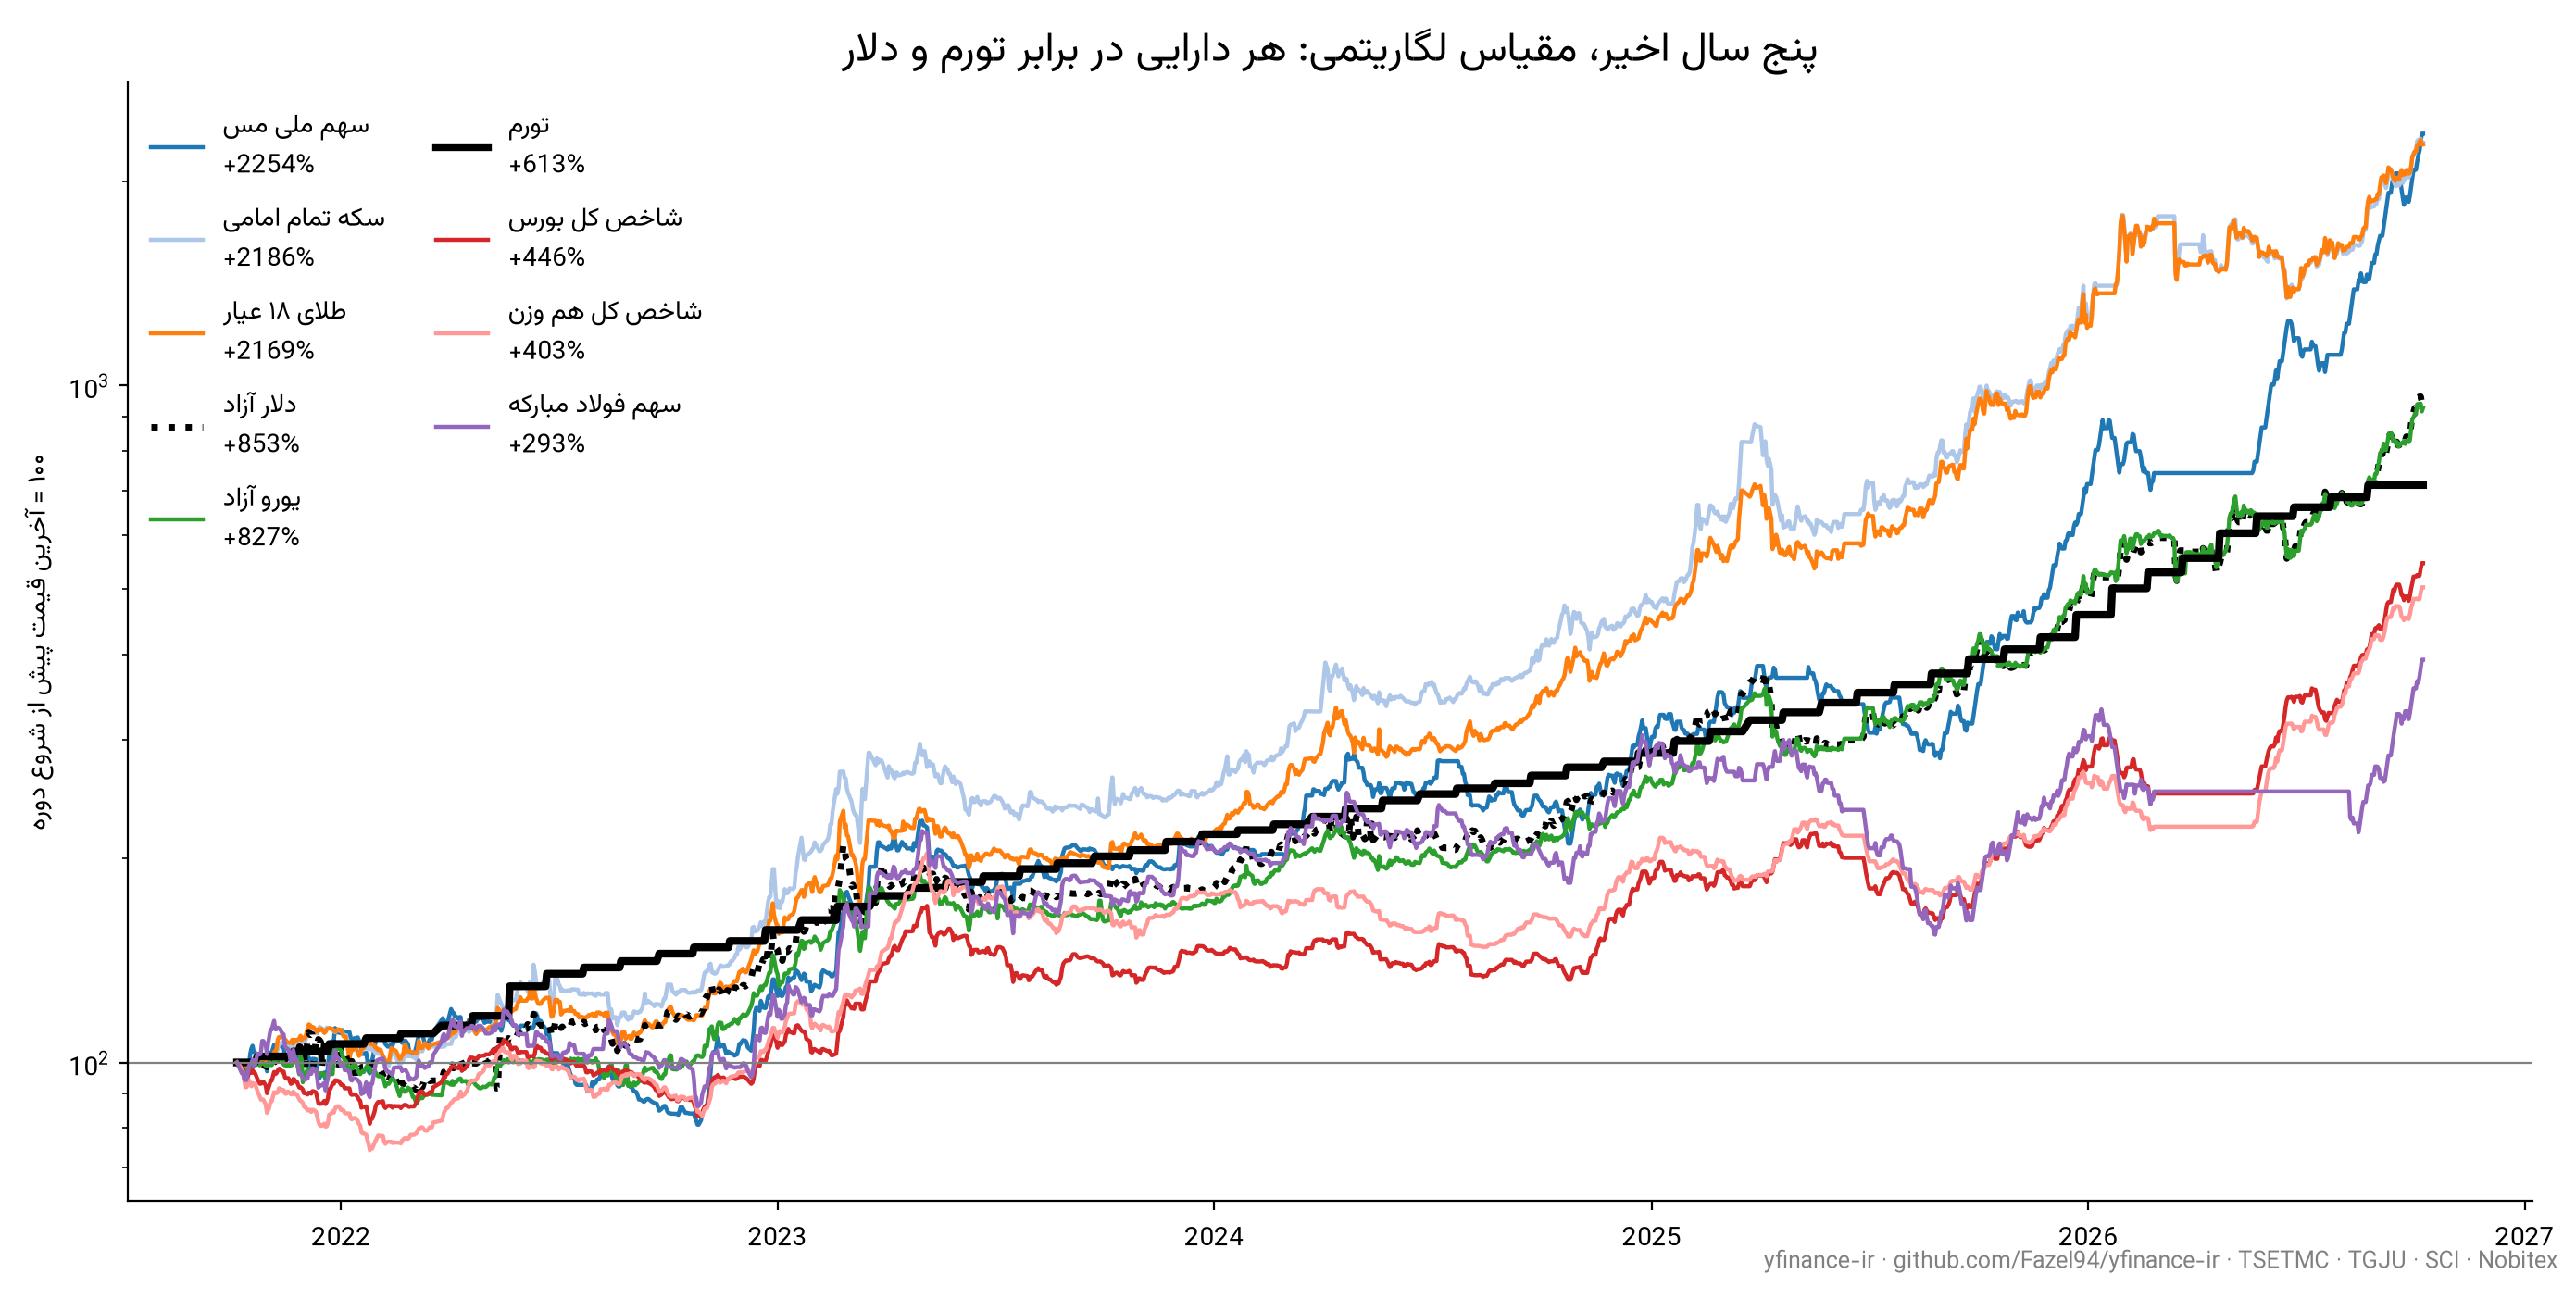

not on this chart, data starts after the window opens: صندوق اهرمی اهرم, صندوق درآمد ثابت آوند, بیت کوین (نوبیتکس)


In [7]:
race(TODAY - pd.DateOffset(years=5), "پنج سال اخیر، مقیاس لگاریتمی: هر دارایی در برابر تورم و دلار", log=True)

## Does it hold on other horizons?

CPI-deflated and dollar total returns over seven windows ending at the latest bar, assets
in scoreboard order. Red is behind the yardstick, green ahead. The colour saturates at
±100% so bitcoin and the leveraged ETF do not wash out the rest; the number in the cell
is the true value. A dash means the asset has no quote before that window opens. A symbol that
was still closed when a window opened is measured from its last trade before the closure, so its
short-window cells repeat its move since reopening.

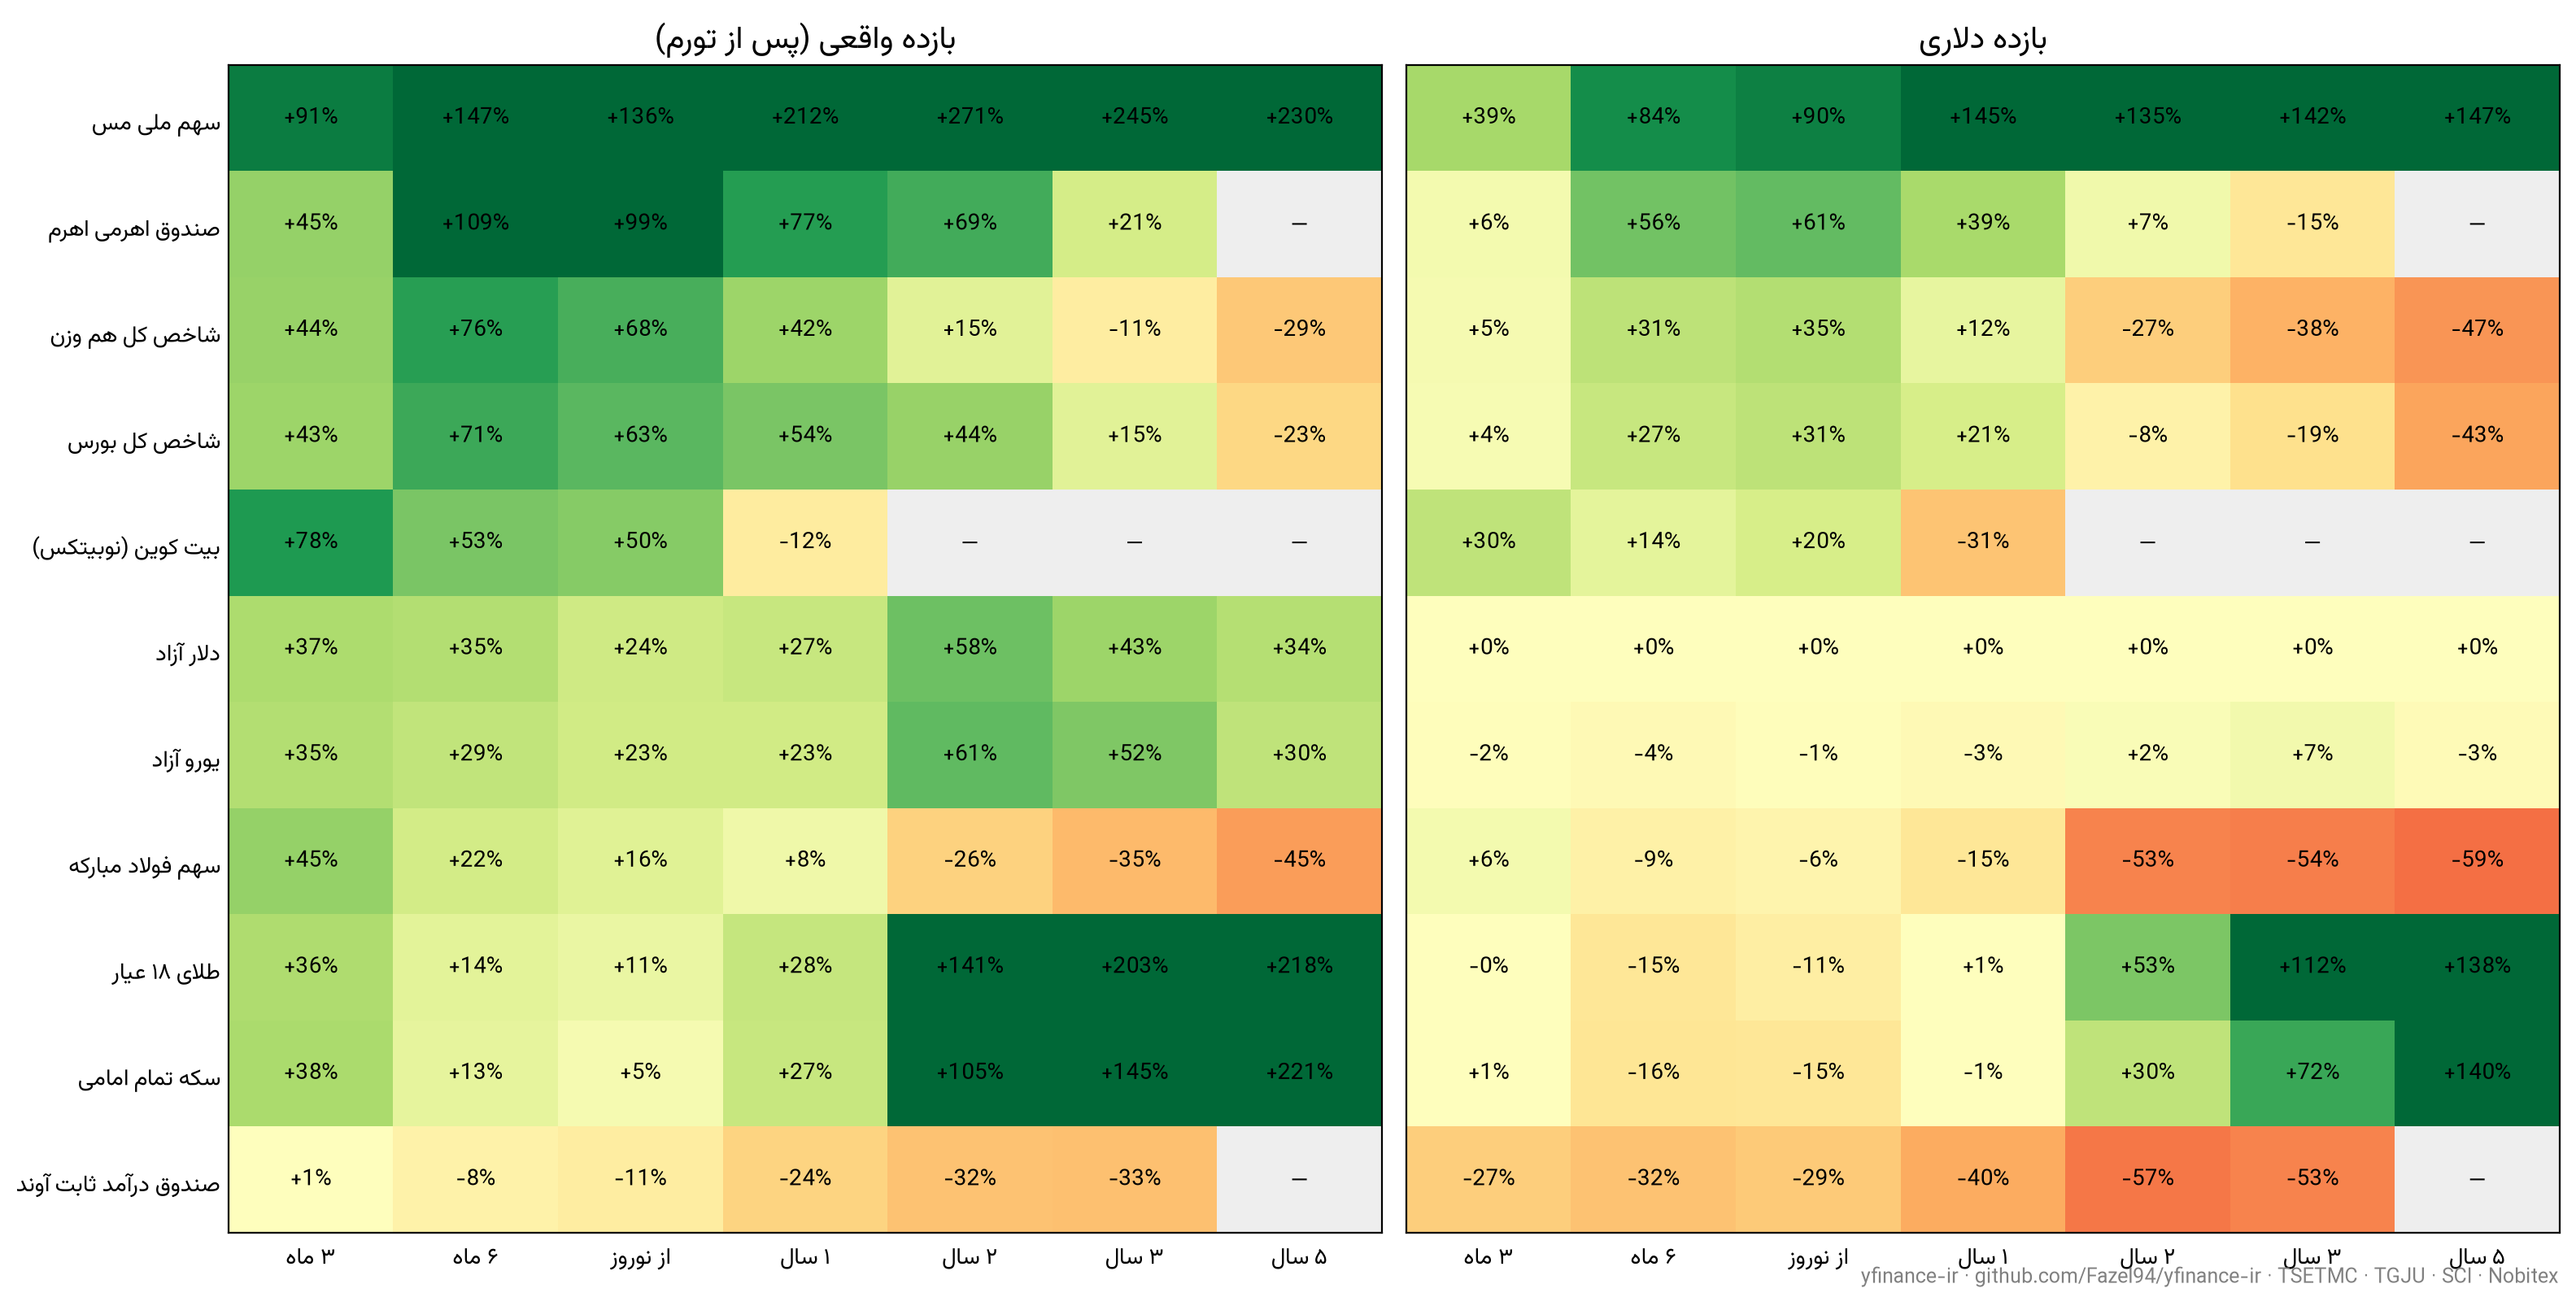

In [8]:
WINDOWS = {
    "۳ ماه": TODAY - pd.DateOffset(months=3),
    "۶ ماه": TODAY - pd.DateOffset(months=6),
    "از نوروز": NOWRUZ,
    "۱ سال": TODAY - pd.DateOffset(years=1),
    "۲ سال": TODAY - pd.DateOffset(years=2),
    "۳ سال": TODAY - pd.DateOffset(years=3),
    "۵ سال": TODAY - pd.DateOffset(years=5),
}
per_window = {name: window_returns(start)[0] for name, start in WINDOWS.items()}
order = ytd.sort_values("nominal", ascending=False).index
real = pd.DataFrame({name: t["real"] for name, t in per_window.items()}).loc[order]
in_usd = pd.DataFrame({name: t["usd"] for name, t in per_window.items()}).loc[order]


def heatmap(ax, frame, title):
    cmap = plt.get_cmap("RdYlGn").copy()
    cmap.set_bad("#eeeeee")
    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    ax.imshow(frame.clip(-1, 1).to_numpy(dtype=float), cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(frame.shape[1]), [fa(c) for c in frame.columns])
    ax.set_yticks(range(frame.shape[0]), [fa(r) for r in frame.index])
    for i in range(frame.shape[0]):
        for j in range(frame.shape[1]):
            v = frame.iat[i, j]
            ax.text(j, i, "—" if pd.isna(v) else f"{v:+.0%}", ha="center", va="center", fontsize=10)
    ax.set_title(fa(title), fontsize=14)
    ax.tick_params(length=0)


fig, axes = plt.subplots(1, 2, figsize=(16, 0.55 * len(order) + 2), sharey=True)
heatmap(axes[0], real, "بازده واقعی (پس از تورم)")
heatmap(axes[1], in_usd, "بازده دلاری")
fig.text(0.99, 0.005, CREDIT, ha="right", va="bottom", fontsize=9, color="grey")
fig.tight_layout()
plt.show()

## What the data says

1405 opened with the exchange shut. The last trades before Nowruz are from 6 Esfand 1404
(25 February); the two indices, ملی مس and اهرم first moved again on 29 Ordibehesht (19 May)
and فولاد مبارکه on 17 Mordad (8 August). Until then their lines in the race charts are flat,
and every TSETMC return below is measured from the 6 Esfand close. The dollar, gold and
bitcoin traded throughout.

Since the last quote of 1404 the free-market dollar is up 67.1% and the CPI 34.6%: the Rial
lost more against the dollar than against the consumer basket, so every asset that beat the
dollar also beat inflation.

Five assets beat both (nominal / real / dollar): ملی مس +217.2% / +135.7% / +89.8%, the
leveraged fund اهرم +168.4% / +99.5% / +60.6%, the equal-weight index +125.7% / +67.7% / +35.1%,
the main index +118.9% / +62.7% / +31.0% and bitcoin +101.2% / +49.5% / +20.4%. Four beat
inflation and lost to the dollar: the euro +65.7% / +23.1% / −0.8%, فولاد مبارکه +56.5% /
+16.3% / −6.3%, 18-carat gold +49.1% / +10.8% / −10.8% and the Emami coin +41.5% / +5.2% /
−15.3%. The fixed-income fund آوند lost to both: +19.2% nominal, −11.4% real, −28.7% in
dollars.

Stock returns are total returns. The reopening bars of فولاد and ملی مس book the dividends and
bonus shares approved while they were closed (`history(auto_adjust=False)` shows share factors
of 1.29 and 1.37 plus 55 and 450 Rial of dividends), so they run well above the raw price
change: فولاد's quoted price is up about 19% from 6 Esfand.

Over five years, at the right edge, ملی مس (+2254%), the coin (+2186%), gold (+2169%), the
dollar (+853%) and the euro (+827%) end above the CPI line (+613%); the main index (+446%),
the equal-weight index (+403%) and فولاد (+293%) end below it.

The latest CPI month is Shahrivar 1405 (729.8, +4.2% m/m, point-to-point +89.8%), taken from
SCI's 8 Mehr report because the workbook still ends at Mordad. It is forward-filled to the
last bar, so the weeks of Mehr carry no inflation and every real return above is two to three
points too high at Shahrivar's monthly pace. That matters for one row only: the coin's +5.2%
real return would be roughly +2–3%, ahead of inflation but barely.